# Auditor Opinion Forecasting: Financial-Only and Prior-Opinion Models (v2)

## Setup

In [7]:
import hashlib
import importlib
import json
import pickle
import platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, brier_score_loss, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RANDOM_SEED = 42
N_BOOTSTRAP = 1000
DATA_PATH = Path("final_panel 1.csv")
MODEL_DIR = Path("models")
RESULTS_DIR = Path("results")
MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

FEATURE_COLS = [
    "LNEMP", "LNTA", "LNSALE", "LNTI", "IntanTA", "InvCA", "CapInt",
    "TobinQ", "RET1Y", "ROA", "ROE", "GPM", "CURR_RATIO", "AT_TURN",
    "INV_TURN", "DPR", "PTB", "PE", "cfsale",
]
PRIOR_COL = "prior_adverse_opinion"
FINANCIAL_ONLY = list(FEATURE_COLS)
WITH_PRIOR = FEATURE_COLS + [PRIOR_COL]

DEV_YEARS = (2011, 2017)
TRAIN_YEARS = (2011, 2015)
VAL_YEARS = (2016, 2017)
TEST_YEARS = (2018, 2021)
TEST_OUTCOME_YEARS = [2019, 2020, 2021, 2022]

PRIMARY = "XGBoost"
VARIANT = "XGBoost + prior opinion"

print("Random seed:", RANDOM_SEED, "| bootstrap draws:", N_BOOTSTRAP)
print("Versions: python", platform.python_version(), "| pandas", pd.__version__,
      "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__)

Random seed: 42 | bootstrap draws: 1000
Versions: python 3.13.5 | pandas 2.2.3 | numpy 2.1.3 | sklearn 1.6.1 | xgboost 3.2.0


In [8]:
def prepare_features(frame):
    """Task 1.3 rule: cfsale = oibdp / sale, zero sales treated as missing; infinite values become missing."""
    out = frame.copy()
    sales = pd.to_numeric(out["sale"], errors="raise")
    income = pd.to_numeric(out["oibdp"], errors="raise")
    out["cfsale"] = income / sales.replace(0, np.nan)
    out[FEATURE_COLS] = (
        out[FEATURE_COLS].apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
    )
    return out


def log_odds(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def pr_auc(y, p):
    precision, recall, _ = precision_recall_curve(y, p)
    return auc(recall, precision)


def metric_row(model, subgroup, y, p):
    y = np.asarray(y)
    p = np.asarray(p, dtype=float)
    return {
        "model": model,
        "subgroup": subgroup,
        "rows": int(len(y)),
        "adverse": int(y.sum()),
        "observed_rate": float(y.mean()),
        "mean_predicted": float(p.mean()),
        "ROC_AUC": roc_auc_score(y, p),
        "PR_AUC": pr_auc(y, p),
        "Brier": brier_score_loss(y, p),
    }


def bootstrap_ci(y, p, n=N_BOOTSTRAP, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    p = np.asarray(p, dtype=float)
    roc, pra = [], []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        yb = y[idx]
        if yb.sum() == 0:
            continue
        roc.append(roc_auc_score(yb, p[idx]))
        pra.append(pr_auc(yb, p[idx]))
    return {
        "ROC_lo": np.percentile(roc, 2.5), "ROC_hi": np.percentile(roc, 97.5),
        "PR_lo": np.percentile(pra, 2.5), "PR_hi": np.percentile(pra, 97.5),
    }


def bootstrap_gap(y, p_base, p_new, n=N_BOOTSTRAP, seed=RANDOM_SEED):
    """Gap = new model minus base model, on identical bootstrap resamples."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    p_base = np.asarray(p_base, dtype=float)
    p_new = np.asarray(p_new, dtype=float)
    roc, pra = [], []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        yb = y[idx]
        if yb.sum() == 0:
            continue
        roc.append(roc_auc_score(yb, p_new[idx]) - roc_auc_score(yb, p_base[idx]))
        pra.append(pr_auc(yb, p_new[idx]) - pr_auc(yb, p_base[idx]))
    return {
        "ROC_gap": roc_auc_score(y, p_new) - roc_auc_score(y, p_base),
        "ROC_lo": np.percentile(roc, 2.5), "ROC_hi": np.percentile(roc, 97.5),
        "PR_gap": pr_auc(y, p_new) - pr_auc(y, p_base),
        "PR_lo": np.percentile(pra, 2.5), "PR_hi": np.percentile(pra, 97.5),
    }


def show(df, digits=4):
    print(df.round(digits).to_string(index=False))

## Load the panel

In [9]:
raw = pd.read_csv(
    DATA_PATH,
    dtype={"gvkey": "string", "cik": "string", "cusip": "string", "tic": "string"},
    parse_dates=["datadate", "INFO_DATE"],
)

## Task 1.1: Label filter

Only assessed firm-years are kept: auopic 1 (effective internal controls) and 2 (adverse opinion). Code 0, codes 3 and 4, and missing labels are excluded and counted so the filter reconciles to the full panel.

In [10]:
print("Loaded:", f"{len(raw):,}", "rows |", f"{raw.gvkey.nunique():,}", "firms | FY",
      raw.fyear.min(), "-", raw.fyear.max())
print("SHA256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())

assert raw[["gvkey", "fyear"]].notna().all().all(), "Missing firm identifiers or fiscal years."
assert not raw.duplicated(["gvkey", "fyear"]).any(), "Duplicate firm-year observations."

print("\nOriginal auopic counts (including missing):")
print(raw["auopic"].value_counts(dropna=False).sort_index().to_string())

assessed = raw.loc[raw["auopic"].isin([1, 2])].copy()
exclusions = {
    "Code 0 (unknown or SOX exempt)": int(raw["auopic"].eq(0).sum()),
    "Codes 3 and 4": int(raw["auopic"].isin([3, 4]).sum()),
    "Missing label": int(raw["auopic"].isna().sum()),
}
assert len(assessed) + sum(exclusions.values()) == len(raw), "Exclusions do not reconcile."

print("\nExcluded rows:")
for k, v in exclusions.items():
    print(f"  {k}: {v:,}")
n_adverse_assessed = int(assessed["auopic"].eq(2).sum())
print(f"\nRetained firm-years: {len(assessed):,} (effective {len(assessed) - n_adverse_assessed:,}, "
      f"adverse {n_adverse_assessed:,})")
print(f"Adverse rate among assessed firm-years: {n_adverse_assessed / len(assessed):.2%}")

Loaded: 83,726 rows | 12,275 firms | FY 2011 - 2022
SHA256: 482b5947612a99a6e3d9c0e5d09f781442967bf2d1f209db8ff48add16aac788

Original auopic counts (including missing):
auopic
0.0    40802
1.0    40719
2.0     2009
3.0        4
4.0        3
NaN      189

Excluded rows:
  Code 0 (unknown or SOX exempt): 40,802
  Codes 3 and 4: 7
  Missing label: 189

Retained firm-years: 42,728 (effective 40,719, adverse 2,009)
Adverse rate among assessed firm-years: 4.70%


SHA256: 482b5947612a99a6e3d9c0e5d09f781442967bf2d1f209db8ff48add16aac788

Original auopic counts (including missing):
auopic
0.0    40802
1.0    40719
2.0     2009
3.0        4
4.0        3
NaN      189

Excluded rows:
  Code 0 (unknown or SOX exempt): 40,802
  Codes 3 and 4: 7
  Missing label: 189

Retained firm-years: 42,728 (effective 40,719, adverse 2,009)
Adverse rate among assessed firm-years: 4.70%


## Task 1.2: Next-year outcome pairs

Fiscal-year t features predict the fiscal-year t+1 opinion. A pair is kept only when the same firm has an assessed opinion in exactly year t+1. The prediction date is the feature year's INFO_DATE. 

In [11]:
assessed["target"] = (assessed["auopic"] == 2).astype(int)
assessed["feature_year"] = assessed["fyear"].astype(int)
assessed["prediction_date"] = assessed["INFO_DATE"]
assessed[PRIOR_COL] = assessed["target"]

outcomes = assessed[["gvkey", "feature_year", "INFO_DATE", "target"]].rename(columns={
    "feature_year": "outcome_year",
    "INFO_DATE": "outcome_info_date",
    "target": "outcome_target",
})

pairs = assessed.copy()
pairs["outcome_year"] = pairs["feature_year"] + 1
pairs = pairs.merge(outcomes, on=["gvkey", "outcome_year"], how="inner", validate="one_to_one")
pairs["target"] = pairs["outcome_target"].astype(int)
pairs = pairs.sort_values(["prediction_date", "gvkey"]).reset_index(drop=True)

assert (pairs["outcome_year"] == pairs["feature_year"] + 1).all(), "Outcome is not exactly t+1."
assert pairs["prediction_date"].lt(pairs["outcome_info_date"]).all(), "Prediction date must precede outcome date."
assert not pairs.duplicated(["gvkey", "feature_year"]).any()

unmatched = len(assessed) - len(pairs)
print(f"Assessed feature-year rows: {len(assessed):,}")
print(f"Without an exact next-year assessed opinion: {unmatched:,}")
print(f"Retained consecutive-year pairs: {len(pairs):,} across {pairs.gvkey.nunique():,} firms")
print(f"Next-year adverse outcomes: {int(pairs.target.sum()):,} ({pairs.target.mean():.2%})")

Assessed feature-year rows: 42,728
Without an exact next-year assessed opinion: 6,482
Retained consecutive-year pairs: 36,246 across 5,353 firms
Next-year adverse outcomes: 1,433 (3.95%)


## Task 1.3: Feature table

The 19 financial predictors are built from the original unsuffixed columns. cfsale is oibdp divided by sale, with zero sales treated as missing. 

In [12]:
pairs = prepare_features(pairs)

n_zero_sales = int(pd.to_numeric(pairs["sale"]).eq(0).sum())
n_finite_cfsale = int(pairs["cfsale"].notna().sum())
print(f"Zero-sales pairs: {n_zero_sales:,}")
print(f"Finite cfsale: {n_finite_cfsale:,} / {len(pairs):,} ({n_finite_cfsale / len(pairs):.2%})")

missingness = pd.DataFrame({
    "missing_rows": pairs[FEATURE_COLS].isna().sum(),
    "missing_percent": pairs[FEATURE_COLS].isna().mean() * 100,
}).sort_values("missing_percent", ascending=False)
print("\nMissingness before imputation (pooled, pre-split):")
print(missingness.round(2).to_string())

Zero-sales pairs: 426
Finite cfsale: 34,186 / 36,246 (94.32%)

Missingness before imputation (pooled, pre-split):
            missing_rows  missing_percent
INV_TURN           10372            28.62
DPR                 9065            25.01
InvCA               8659            23.89
CURR_RATIO          8295            22.89
CapInt              2511             6.93
PTB                 2354             6.49
cfsale              2060             5.68
ROA                 1751             4.83
ROE                 1599             4.41
RET1Y               1031             2.84
PE                   911             2.51
TobinQ               808             2.23
LNEMP                583             1.61
LNTI                 578             1.59
IntanTA              528             1.46
GPM                  452             1.25
AT_TURN              124             0.34
LNSALE                26             0.07
LNTA                   0             0.00


## Task 1.4: Temporal split (Enoch Banda, reviewed)

This follows Enoch's revised split. Feature year t predicts outcome year t+1.

In [13]:
development = pairs.loc[pairs["feature_year"].between(*DEV_YEARS)]
train_candidates = development.loc[development["feature_year"].between(*TRAIN_YEARS)].copy()
val_candidates = development.loc[development["feature_year"].between(*VAL_YEARS)].copy()
test_candidates = pairs.loc[pairs["feature_year"].between(*TEST_YEARS)].copy()

val_start = val_candidates["prediction_date"].min()
test_start = test_candidates["prediction_date"].min()

X_train = (train_candidates.loc[train_candidates["outcome_info_date"] < val_start]
           .sort_values(["prediction_date", "gvkey"]).reset_index(drop=True))
X_val = (val_candidates.loc[val_candidates["outcome_info_date"] < test_start]
         .sort_values(["prediction_date", "gvkey"]).reset_index(drop=True))
X_test = test_candidates.sort_values(["prediction_date", "gvkey"]).reset_index(drop=True)

for name, part in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    assert (part["outcome_year"] == part["feature_year"] + 1).all(), f"{name}: t+1 check failed."
    assert part["target"].nunique() == 2, f"{name}: both classes are required."

assert X_train["outcome_info_date"].max() < X_val["prediction_date"].min(), "Train labels overlap validation."
assert X_val["outcome_info_date"].max() < X_test["prediction_date"].min(), "Validation labels overlap test."
assert set(X_train["feature_year"]).isdisjoint(X_val["feature_year"])
assert set(X_val["feature_year"]).isdisjoint(X_test["feature_year"])

def split_summary(part, name):
    return {
        "partition": name,
        "rows": int(len(part)),
        "firms": int(part["gvkey"].nunique()),
        "feature_years": f"{int(part.feature_year.min())}-{int(part.feature_year.max())}",
        "outcome_years": f"{int(part.outcome_year.min())}-{int(part.outcome_year.max())}",
        "prediction_dates": f"{part.prediction_date.min().date()} to {part.prediction_date.max().date()}",
        "adverse": int(part["target"].sum()),
        "adverse_rate": float(part["target"].mean()),
    }

split_table = pd.DataFrame([
    split_summary(X_train, "Training"),
    split_summary(X_val, "Validation"),
    split_summary(X_test, "Test"),
])
print(f"Timing exclusions: training {len(train_candidates) - len(X_train):,}, "
      f"validation {len(val_candidates) - len(X_val):,}")
show(split_table)
split_table.to_csv(RESULTS_DIR / "split_summary_v2.csv", index=False)

split_record = {
    "design": "Feature year t predicts outcome year t+1 (auopic = 2)",
    "source": "Enoch Banda, Task 1.4, reviewed",
    "timing_rule": "Earlier partition outcome INFO_DATE must precede the next partition's earliest prediction date",
    "info_date_limitation": "INFO_DATE is an availability proxy, not a verified auditor report date",
    "partitions": split_table.to_dict("records"),
}

Timing exclusions: training 3,365, validation 3,211
 partition  rows  firms feature_years outcome_years         prediction_dates  adverse  adverse_rate
  Training 14092   4136     2011-2014     2012-2015 2011-09-30 to 2015-08-31      522        0.0370
Validation  3253   3253     2016-2016     2017-2017 2016-09-30 to 2017-08-31      116        0.0357
      Test 12325   3785     2018-2021     2019-2022 2018-09-30 to 2022-08-31      471        0.0382


## Task 1.5A: Model fitting on training data

Five models are fitted on training data only: logistic regression, Random Forest, and XGBoost on financial predictors, plus the Random Forest and XGBoost with the prior-opinion indicator. Each pipeline fits median imputation with missing indicators on training data. The logistic regression also standardizes its inputs. Hyperparameters are fixed before validation results are seen.

In [14]:
def make_lr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000, class_weight=None, random_state=RANDOM_SEED)),
    ])

def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("classifier", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=10, max_features="sqrt",
            class_weight=None, random_state=RANDOM_SEED, n_jobs=-1)),
    ])

def make_xgb():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("classifier", XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.05, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist",
            random_state=RANDOM_SEED, n_jobs=2)),
    ])

SPECS = {
    "Logistic regression": (make_lr, FINANCIAL_ONLY),
    "Random Forest": (make_rf, FINANCIAL_ONLY),
    PRIMARY: (make_xgb, FINANCIAL_ONLY),
    "Random Forest + prior opinion": (make_rf, WITH_PRIOR),
    VARIANT: (make_xgb, WITH_PRIOR),
}

y_train = X_train["target"].to_numpy()
y_val = X_val["target"].to_numpy()
y_test = X_test["target"].to_numpy()

fitted = {}
for name, (builder, cols) in SPECS.items():
    fitted[name] = (builder().fit(X_train[cols], y_train), cols)
print("Fitted:", ", ".join(fitted))

Fitted: Logistic regression, Random Forest, XGBoost, Random Forest + prior opinion, XGBoost + prior opinion


## Task 1.5B: Validation comparison

The primary model is the financial-only model with the highest validation ROC-AUC among logistic regression, Random Forest and XGBoost. 

In [15]:
val_scores = {name: fitted[name][0].predict_proba(X_val[fitted[name][1]])[:, 1] for name in SPECS}
val_table = pd.DataFrame([metric_row(n, "Validation", y_val, val_scores[n]) for n in SPECS])
show(val_table)

leader = max(["Logistic regression", "Random Forest", "XGBoost"], key=lambda n: roc_auc_score(y_val, val_scores[n]))
assert leader == PRIMARY, f"Pre-specified rule selects {leader}, not {PRIMARY}."
gap_rf = bootstrap_gap(y_val, val_scores["Random Forest"], val_scores[PRIMARY])
print(f"\nPrimary (highest validation ROC-AUC among financial-only models): {PRIMARY}")
print(f"XGBoost minus Random Forest on validation: ROC {gap_rf['ROC_gap']:.4f} "
      f"[{gap_rf['ROC_lo']:.4f}, {gap_rf['ROC_hi']:.4f}]")
val_table.to_csv(RESULTS_DIR / "validation_metrics_v2.csv", index=False)

                        model   subgroup  rows  adverse  observed_rate  mean_predicted  ROC_AUC  PR_AUC  Brier
          Logistic regression Validation  3253      116         0.0357          0.0379   0.6433  0.0592 0.0343
                Random Forest Validation  3253      116         0.0357          0.0379   0.7186  0.0925 0.0335
                      XGBoost Validation  3253      116         0.0357          0.0356   0.7195  0.0853 0.0337
Random Forest + prior opinion Validation  3253      116         0.0357          0.0421   0.7892  0.2254 0.0306
      XGBoost + prior opinion Validation  3253      116         0.0357          0.0397   0.7958  0.2390 0.0303

Primary (highest validation ROC-AUC among financial-only models): XGBoost
XGBoost minus Random Forest on validation: ROC 0.0008 [-0.0257, 0.0263]



Primary (highest validation ROC-AUC among financial-only models): XGBoost
XGBoost minus Random Forest on validation: ROC 0.0045 [-0.0219, 0.0294]


## Task 1.5C: Calibration (fitted on validation only)



XGBoost:
  observed validation rate 3.57% | mean raw 3.56% | mean calibrated 3.56%
  Brier raw 0.03366 | Brier calibrated 0.03357
XGBoost + prior opinion:
  observed validation rate 3.57% | mean raw 3.97% | mean calibrated 3.56%
  Brier raw 0.03033 | Brier calibrated 0.03017


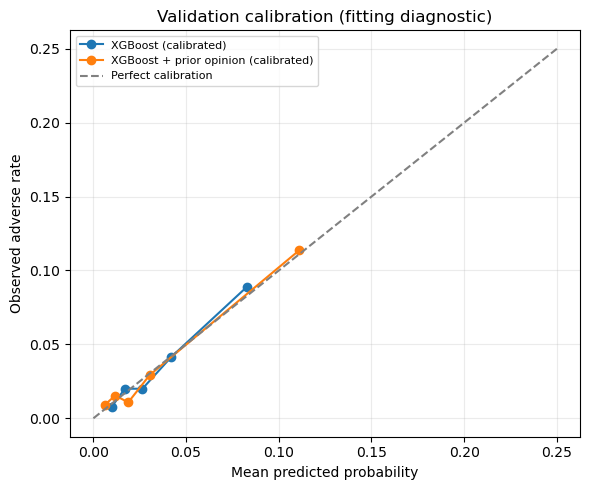

In [16]:
calibrators = {}
for name in [PRIMARY, VARIANT]:
    cal = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000, random_state=RANDOM_SEED)
    cal.fit(log_odds(val_scores[name]), y_val)
    assert cal.coef_[0, 0] > 0, f"{name}: calibration reversed the ranking."
    calibrators[name] = cal

for name in [PRIMARY, VARIANT]:
    cal_val = calibrators[name].predict_proba(log_odds(val_scores[name]))[:, 1]
    print(f"{name}:")
    print(f"  observed validation rate {y_val.mean():.2%} | mean raw {val_scores[name].mean():.2%} "
          f"| mean calibrated {cal_val.mean():.2%}")
    print(f"  Brier raw {brier_score_loss(y_val, val_scores[name]):.5f} "
          f"| Brier calibrated {brier_score_loss(y_val, cal_val):.5f}")

fig, ax = plt.subplots(figsize=(6, 5))
for name in [PRIMARY, VARIANT]:
    cal_val = calibrators[name].predict_proba(log_odds(val_scores[name]))[:, 1]
    obs, pred = calibration_curve(y_val, cal_val, n_bins=5, strategy="quantile")
    ax.plot(pred, obs, marker="o", label=f"{name} (calibrated)")
ax.plot([0, 0.25], [0, 0.25], "--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed adverse rate")
ax.set_title("Validation calibration (fitting diagnostic)")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validation_calibration_v2.png", dpi=200)
plt.show()

## Task 1.5D: Test evaluation (pooled and by outcome year)


In [17]:
test_scores = {name: fitted[name][0].predict_proba(X_test[fitted[name][1]])[:, 1] for name in SPECS}
test_cal = {name: calibrators[name].predict_proba(log_odds(test_scores[name]))[:, 1] for name in [PRIMARY, VARIANT]}

groups = [("Pooled 2019-2022", np.ones(len(X_test), dtype=bool))]
groups += [(f"Outcome {y}", X_test["outcome_year"].to_numpy() == y) for y in TEST_OUTCOME_YEARS]

rows = []
for label, mask in groups:
    yy = y_test[mask]
    for name in SPECS:
        rows.append(metric_row(f"{name} (raw)", label, yy, test_scores[name][mask]))
    for name in [PRIMARY, VARIANT]:
        rows.append(metric_row(f"{name} (calibrated)", label, yy, test_cal[name][mask]))
    constant = np.full(mask.sum(), y_train.mean())
    rows.append({"model": "Constant prevalence benchmark", "subgroup": label,
                 "rows": int(mask.sum()), "adverse": int(yy.sum()),
                 "observed_rate": float(yy.mean()), "mean_predicted": float(constant.mean()),
                 "ROC_AUC": np.nan, "PR_AUC": np.nan,
                 "Brier": brier_score_loss(yy, constant)})

test_table = pd.DataFrame(rows)
show(test_table)
test_table.to_csv(RESULTS_DIR / "test_metrics_v2.csv", index=False)

ci_rows, gap_rows = [], []
for label, mask in groups:
    yy = y_test[mask]
    for name in [PRIMARY, VARIANT]:
        b = bootstrap_ci(yy, test_cal[name][mask])
        ci_rows.append({"model": name, "subgroup": label, **b})
    g = bootstrap_gap(yy, test_cal[PRIMARY][mask], test_cal[VARIANT][mask])
    gap_rows.append({"subgroup": label, **g})

ci_table = pd.DataFrame(ci_rows)
gap_table = pd.DataFrame(gap_rows)
print("\nBootstrap 95% intervals (calibrated probabilities):")
show(ci_table)
print("Gap: prior-opinion model minus primary model (calibrated):")
show(gap_table)
ci_table.to_csv(RESULTS_DIR / "test_bootstrap_ci_v2.csv", index=False)
gap_table.to_csv(RESULTS_DIR / "test_model_gap_v2.csv", index=False)

                               model         subgroup  rows  adverse  observed_rate  mean_predicted  ROC_AUC  PR_AUC  Brier
           Logistic regression (raw) Pooled 2019-2022 12325      471         0.0382          0.0360   0.6591  0.0703 0.0364
                 Random Forest (raw) Pooled 2019-2022 12325      471         0.0382          0.0401   0.6846  0.0934 0.0360
                       XGBoost (raw) Pooled 2019-2022 12325      471         0.0382          0.0345   0.6914  0.0891 0.0360
 Random Forest + prior opinion (raw) Pooled 2019-2022 12325      471         0.0382          0.0424   0.7970  0.2977 0.0308
       XGBoost + prior opinion (raw) Pooled 2019-2022 12325      471         0.0382          0.0376   0.8039  0.2939 0.0306
                XGBoost (calibrated) Pooled 2019-2022 12325      471         0.0382          0.0348   0.6914  0.0891 0.0360
XGBoost + prior opinion (calibrated) Pooled 2019-2022 12325      471         0.0382          0.0339   0.8039  0.2939 0.0309
       C


Bootstrap 95% intervals (calibrated probabilities):
                  model         subgroup  ROC_lo  ROC_hi  PR_lo  PR_hi
                XGBoost Pooled 2019-2022  0.6648  0.7118 0.0740 0.1120
XGBoost + prior opinion Pooled 2019-2022  0.7843  0.8330 0.2518 0.3419
                XGBoost     Outcome 2019  0.6400  0.7261 0.0683 0.1383
XGBoost + prior opinion     Outcome 2019  0.7553  0.8419 0.2089 0.3581
                XGBoost     Outcome 2020  0.6395  0.7450 0.0475 0.1257
XGBoost + prior opinion     Outcome 2020  0.7499  0.8588 0.1620 0.3245
                XGBoost     Outcome 2021  0.6176  0.7184 0.0362 0.1043
XGBoost + prior opinion     Outcome 2021  0.7872  0.8767 0.1604 0.3308
                XGBoost     Outcome 2022  0.6617  0.7455 0.0912 0.1691
XGBoost + prior opinion     Outcome 2022  0.7639  0.8494 0.3253 0.4992
Gap: prior-opinion model minus primary model (calibrated):
        subgroup  ROC_gap  ROC_lo  ROC_hi  PR_gap  PR_lo  PR_hi
Pooled 2019-2022   0.1196  0.1018  0.1382  

### Per-year ROC-AUC chart


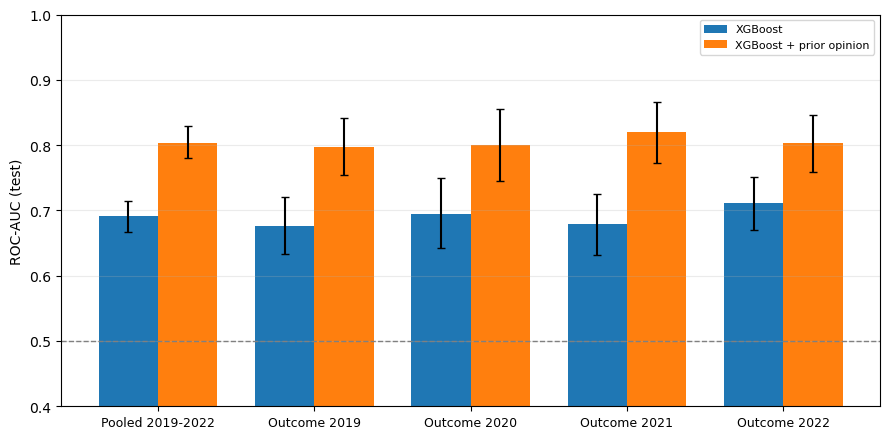

In [18]:
labels = [g[0] for g in groups]
x = np.arange(len(labels))
width = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
for offset, name in [(-width / 2, PRIMARY), (width / 2, VARIANT)]:
    sub = ci_table[ci_table.model == name].set_index("subgroup").loc[labels]
    est = test_table[test_table.model.isin(
        [f"{name} (calibrated)"])
    ].set_index("subgroup").loc[labels]["ROC_AUC"]
    yerr = np.vstack([est.values - sub["ROC_lo"].values, sub["ROC_hi"].values - est.values])
    ax.bar(x + offset, est.values, width, label=name, yerr=yerr, capsize=3)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("ROC-AUC (test)")
ax.set_ylim(0.4, 1.0)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_roc_by_outcome_year_v2.png", dpi=200)
plt.show()

## Task 1.5E: Sensitivity check, relaxed non-overlapping split


In [19]:
relaxed_train = train_candidates
relaxed_val = val_candidates
y_rtrain = relaxed_train["target"].to_numpy()
y_rval = relaxed_val["target"].to_numpy()

relaxed_test = {}
relaxed_info = {}
for name in [PRIMARY, VARIANT]:
    builder, cols = SPECS[name]
    model = builder().fit(relaxed_train[cols], y_rtrain)
    v_raw = model.predict_proba(relaxed_val[cols])[:, 1]
    cal = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000, random_state=RANDOM_SEED)
    cal.fit(log_odds(v_raw), y_rval)
    t_raw = model.predict_proba(X_test[cols])[:, 1]
    relaxed_test[name] = cal.predict_proba(log_odds(t_raw))[:, 1]

print(f"Relaxed training rows: {len(relaxed_train):,} (buffered: {len(X_train):,})")
print(f"Relaxed validation rows: {len(relaxed_val):,}, adverse {int(y_rval.sum())} "
      f"(buffered: {len(X_val):,}, adverse {int(y_val.sum())})")
print(f"Rows restored by relaxing the buffer: "
      f"{(len(relaxed_train) - len(X_train)) + (len(relaxed_val) - len(X_val)):,}")

sens_rows = []
for name in [PRIMARY, VARIANT]:
    sens_rows.append(metric_row(f"{name} (relaxed, calibrated)", "Pooled 2019-2022", y_test, relaxed_test[name]))
    sens_rows.append(metric_row(f"{name} (primary, calibrated)", "Pooled 2019-2022", y_test, test_cal[name]))
sens_table = pd.DataFrame(sens_rows)
show(sens_table)
relaxed_gap = bootstrap_gap(y_test, relaxed_test[PRIMARY], relaxed_test[VARIANT])
print("\nRelaxed split gap (prior minus primary):",
      f"ROC {relaxed_gap['ROC_gap']:.4f} [{relaxed_gap['ROC_lo']:.4f}, {relaxed_gap['ROC_hi']:.4f}],",
      f"PR {relaxed_gap['PR_gap']:.4f} [{relaxed_gap['PR_lo']:.4f}, {relaxed_gap['PR_hi']:.4f}]")
sens_table.to_csv(RESULTS_DIR / "sensitivity_relaxed_split_v2.csv", index=False)

Relaxed training rows: 17,457 (buffered: 14,092)
Relaxed validation rows: 6,464, adverse 273 (buffered: 3,253, adverse 116)
Rows restored by relaxing the buffer: 6,576
                                        model         subgroup  rows  adverse  observed_rate  mean_predicted  ROC_AUC  PR_AUC  Brier
                XGBoost (relaxed, calibrated) Pooled 2019-2022 12325      471         0.0382          0.0421   0.6989  0.0913 0.0360
                XGBoost (primary, calibrated) Pooled 2019-2022 12325      471         0.0382          0.0348   0.6914  0.0891 0.0360
XGBoost + prior opinion (relaxed, calibrated) Pooled 2019-2022 12325      471         0.0382          0.0406   0.8038  0.3072 0.0304
XGBoost + prior opinion (primary, calibrated) Pooled 2019-2022 12325      471         0.0382          0.0339   0.8039  0.2939 0.0309

Relaxed split gap (prior minus primary): ROC 0.1049 [0.0854, 0.1223], PR 0.2159 [0.1786, 0.2539]



Relaxed split gap (prior minus primary): ROC 0.1126 [0.0933, 0.1305], PR 0.2158 [0.1771, 0.2523]


## Task 1.6A: Freeze the models and verify reloading


In [20]:
FROZEN_AT = datetime.now(timezone.utc).isoformat()
SOURCE_SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

def freeze(name, version_id, cols):
    model = fitted[name][0]
    artifact = {
        "model_version": version_id,
        "model_name": name,
        "pipeline": model,
        "calibrator": calibrators[name],
        "feature_cols": list(cols),
        "prior_opinion_col": PRIOR_COL if PRIOR_COL in cols else None,
        "default_probability": "calibrated",
        "calibration_transform": {"method": "sigmoid applied to log-odds", "clip_min": 1e-6, "clip_max": 1 - 1e-6},
        "target_definition": "Fiscal-year t+1 auopic equals 2",
        "split_definition": split_record,
        "test_pooled": test_table[(test_table.subgroup == "Pooled 2019-2022")].to_dict("records"),
        "source_file": DATA_PATH.name,
        "source_sha256": SOURCE_SHA,
        "random_seed": RANDOM_SEED,
        "frozen_at_utc": FROZEN_AT,
        "versions": {
            "python": platform.python_version(), "pandas": pd.__version__,
            "numpy": np.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__,
        },
    }
    path = MODEL_DIR / f"{version_id}.pkl"
    with path.open("wb") as f:
        pickle.dump(artifact, f, protocol=pickle.HIGHEST_PROTOCOL)
    return path

primary_path = freeze(PRIMARY, "financial_only_xgb_v2", FINANCIAL_ONLY)
variant_path = freeze(VARIANT, "prior_opinion_xgb_v2", WITH_PRIOR)

for path, name, cols in [(primary_path, PRIMARY, FINANCIAL_ONLY), (variant_path, VARIANT, WITH_PRIOR)]:
    with path.open("rb") as f:
        art = pickle.load(f)
    raw_p = art["pipeline"].predict_proba(X_test[art["feature_cols"]])[:, 1]
    cal_p = art["calibrator"].predict_proba(log_odds(raw_p))[:, 1]
    # XGBoost stores trees in float32, so a reloaded model can differ by about 1e-9 absolute.
    np.testing.assert_allclose(raw_p, test_scores[name], rtol=1e-6, atol=1e-8)
    np.testing.assert_allclose(cal_p, test_cal[name], rtol=1e-6, atol=1e-8)
    print(f"{art['model_version']}: reloaded predictions match test evaluation "
          f"({len(art['feature_cols'])} predictors) -> {path.name}")

decisions = {"split": split_record, "primary": PRIMARY, "variant": VARIANT,
             "frozen_at_utc": FROZEN_AT, "source_sha256": SOURCE_SHA}
(MODEL_DIR / "decisions_v2.json").write_text(json.dumps(decisions, indent=2, default=str), encoding="utf-8")

financial_only_xgb_v2: reloaded predictions match test evaluation (19 predictors) -> financial_only_xgb_v2.pkl
prior_opinion_xgb_v2: reloaded predictions match test evaluation (20 predictors) -> prior_opinion_xgb_v2.pkl


1474

## Task 1.6B: Model card



In [21]:
def md_table(df, columns):
    lines = ["| " + " | ".join(columns) + " |", "|" + "|".join(["---"] * len(columns)) + "|"]
    for _, r in df.iterrows():
        cells = []
        for c in columns:
            v = r[c]
            cells.append(f"{v:.4f}" if isinstance(v, (float, np.floating)) and not np.isnan(v) else
                         ("n/a" if isinstance(v, (float, np.floating)) else str(v)))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

def ci_txt(model, subgroup):
    r = ci_table[(ci_table.model == model) & (ci_table.subgroup == subgroup)].iloc[0]
    return f"{r.ROC_lo:.3f} to {r.ROC_hi:.3f}"

pooled_primary_roc = test_table[(test_table.model == f"{PRIMARY} (calibrated)") & (test_table.subgroup == "Pooled 2019-2022")].ROC_AUC.iloc[0]
pooled_variant_roc = test_table[(test_table.model == f"{VARIANT} (calibrated)") & (test_table.subgroup == "Pooled 2019-2022")].ROC_AUC.iloc[0]
pg = gap_table[gap_table.subgroup == "Pooled 2019-2022"].iloc[0]
target_met = pooled_primary_roc >= 0.826

split_md = md_table(split_table, ["partition", "rows", "firms", "feature_years", "outcome_years", "prediction_dates", "adverse", "adverse_rate"])
val_md = md_table(val_table, ["model", "rows", "adverse", "observed_rate", "mean_predicted", "ROC_AUC", "PR_AUC", "Brier"])
test_md = md_table(test_table, ["model", "subgroup", "rows", "adverse", "observed_rate", "mean_predicted", "ROC_AUC", "PR_AUC", "Brier"])
gap_md = md_table(gap_table, ["subgroup", "ROC_gap", "ROC_lo", "ROC_hi", "PR_gap", "PR_lo", "PR_hi"])
sens_md = md_table(sens_table, ["model", "rows", "adverse", "mean_predicted", "ROC_AUC", "PR_AUC", "Brier"])

ENV_JSON = json.dumps({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__})
card = f"""# Auditor Opinion Forecast Models v2

Frozen at UTC: {FROZEN_AT}

Status: capstone models built on the reviewed temporal split. The project target of 0.826 ROC-AUC on test is {"met" if target_met else "not met"} (primary model pooled test ROC-AUC {pooled_primary_roc:.3f}).

## Prediction task

Use fiscal-year t information to forecast whether a firm receives an adverse internal-control opinion (auopic = 2) in fiscal year t+1. Both years are restricted to auopic codes 1 and 2. This is an internal-control risk indicator, not a fraud finding.

## Models

- Primary: XGBoost (300 trees, maximum depth 3, learning rate 0.05, minimum child weight 5, subsampling 0.8) on 19 financial predictors.
- Variant: the same XGBoost with the fiscal-year t adverse-opinion indicator added (prior-year control opinion).
- Selection rule, fixed before test evaluation: highest validation ROC-AUC among logistic regression, Random Forest and XGBoost on financial predictors.
- Comparators, reported on test: logistic regression (benchmark), Random Forest, and Random Forest with the prior-opinion indicator.
- Preprocessing: median imputation with missing indicators, fitted on training data only.
- Calibration: sigmoid mapping of log-odds, fitted on validation data only.

## Temporal split

{split_md}

Timing rule: an earlier partition's outcome INFO_DATE must precede the next partition's earliest prediction date. Only feature year 2016 survives the validation timing rule. INFO_DATE is an availability proxy, not a verified report date.

## Validation (model selection)

{val_md}

Validation calibration is a fitting diagnostic. It uses 116 adverse cases and is not independent evaluation.

## Test results (outcome years 2019 to 2022)

{test_md}

Bootstrap 95% interval for the primary model's pooled ROC-AUC: {ci_txt(PRIMARY, "Pooled 2019-2022")}.
Bootstrap 95% interval for the variant's pooled ROC-AUC: {ci_txt(VARIANT, "Pooled 2019-2022")}.

## Gap between the two models (prior-opinion variant minus primary, calibrated)

{gap_md}

## Sensitivity: relaxed non-overlapping split

The timing buffer is removed. Training has {len(relaxed_train):,} rows and validation has {len(relaxed_val):,} rows with {int(y_rval.sum())} adverse cases. The test set is unchanged. Training labels in this version can be known after some validation prediction dates, so this is a robustness check only.

{sens_md}

## Limitations

- INFO_DATE is an availability proxy. The auditor report publication date is not verified.
- The test window (outcomes 2019 to 2022) overlaps the period examined in the opinion-history experiment, so test results are not fully clean.
- Validation has 116 adverse cases, so calibration is unstable.
- Per-year test samples are small, 87 to 156 adverse cases. The intervals in the bootstrap table are wide.
- Firms recur across periods, so the test measures future firm-years rather than unseen firms only.
- The prior-opinion variant mostly reflects persistence of control weaknesses. It should be presented as such, and the report should state how much the financial features add beyond it.
- No operating threshold is selected. The score_firm ranking is retrospective, not an as-of-date live ranking.

## Reproducibility

Source file: {DATA_PATH.name}
Source SHA256: {SOURCE_SHA}
Random seed: {RANDOM_SEED}
Bootstrap draws: {N_BOOTSTRAP}
Environment: {ENV_JSON}
Frozen artifacts: models/financial_only_rf_v2.pkl and models/prior_opinion_rf_v2.pkl
"""
(MODEL_DIR / "financial_only_rf_v2_model_card.md").write_text(card, encoding="utf-8")
print("Model card written:", MODEL_DIR / "financial_only_rf_v2_model_card.md")
print(f"Pooled test ROC-AUC, primary {pooled_primary_roc:.4f}, variant {pooled_variant_roc:.4f}")

Model card written: models/financial_only_rf_v2_model_card.md
Pooled test ROC-AUC, primary 0.6914, variant 0.8039


## Task 1.6C: Scoring module

`score_firm` returns the frozen model's probability for one firm-year and its rank among assessed firms in the same feature year. It works for both artifacts. The prior-opinion indicator is built from the firm's auopic in the feature year when the artifact includes it.

In [22]:
SCORING_SRC = r'''
import numpy as np
import pandas as pd

FEATURE_COLS = [
    "LNEMP", "LNTA", "LNSALE", "LNTI", "IntanTA", "InvCA", "CapInt",
    "TobinQ", "RET1Y", "ROA", "ROE", "GPM", "CURR_RATIO", "AT_TURN",
    "INV_TURN", "DPR", "PTB", "PE", "cfsale",
]


def _normalize_gvkey(value):
    text = str(value).strip()
    if text.endswith(".0"):
        text = text[:-2]
    return text.lstrip("0") or "0"


def _prepare(frame):
    out = frame.copy()
    sales = pd.to_numeric(out["sale"], errors="raise")
    income = pd.to_numeric(out["oibdp"], errors="raise")
    out["cfsale"] = income / sales.replace(0, np.nan)
    out[FEATURE_COLS] = (
        out[FEATURE_COLS].apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
    )
    return out


def score_firm(gvkey, feature_year, panel, artifact):
    """
    Score one firm-year with a frozen model.
    Forecast: adverse internal-control opinion (auopic = 2) in fiscal year t+1.
    Rank: descending risk among assessed firms in feature year t (1 = highest risk).
    """
    year = int(feature_year)
    cols = list(artifact["feature_cols"])
    prior_col = artifact.get("prior_opinion_col")

    cohort = panel.loc[panel["fyear"].eq(year) & panel["auopic"].isin([1, 2])].copy()
    if cohort.empty:
        raise ValueError(f"No assessed firms available for FY{year}.")
    if cohort["gvkey"].isna().any():
        raise ValueError("Missing firm identifiers in the cohort.")

    cohort["_key"] = cohort["gvkey"].map(_normalize_gvkey)
    if cohort["_key"].duplicated().any():
        raise ValueError("Duplicate firm-year identifiers.")
    selected = cohort["_key"].eq(_normalize_gvkey(gvkey))
    if selected.sum() != 1:
        raise ValueError(
            f"Expected one assessed record for gvkey={gvkey}, FY{year}; found {int(selected.sum())}."
        )

    cohort = _prepare(cohort)
    if prior_col:
        cohort[prior_col] = (cohort["auopic"] == 2).astype(int)
    features = cohort[cols].apply(pd.to_numeric, errors="raise")

    raw = artifact["pipeline"].predict_proba(features)[:, 1]
    settings = artifact["calibration_transform"]
    clipped = np.clip(raw, settings["clip_min"], settings["clip_max"])
    calibrated = artifact["calibrator"].predict_proba(
        np.log(clipped / (1 - clipped)).reshape(-1, 1)
    )[:, 1]

    version = artifact["default_probability"]
    if version not in {"original", "calibrated"}:
        raise ValueError("Unknown default probability version.")
    probability = calibrated if version == "calibrated" else raw

    ranks = pd.Series(probability).rank(ascending=False, method="min").astype(int).to_numpy()
    position = int(np.flatnonzero(selected.to_numpy())[0])
    row = cohort.iloc[position]

    return {
        "gvkey": str(row["gvkey"]),
        "feature_year": year,
        "outcome_year": year + 1,
        "prediction_date": pd.Timestamp(row["INFO_DATE"]).isoformat(),
        "model_version": artifact["model_version"],
        "probability": float(probability[position]),
        "probability_version": version,
        "probability_original": float(raw[position]),
        "probability_calibrated": float(calibrated[position]),
        "risk_rank": int(ranks[position]),
        "cohort_size": int(len(cohort)),
        "rank_definition": "Descending risk among assessed firms in the feature year; 1 is highest; ties use minimum rank.",
        "missing_features_imputed": features.columns[features.iloc[position].isna()].tolist(),
        "interpretation": "Retrospective score from the frozen model. The year-wide rank is not an as-of-date live ranking.",
    }
'''
Path("scoring.py").write_text(SCORING_SRC, encoding="utf-8")
print("Wrote scoring.py")

Wrote scoring.py


## Task 1.6D: Scoring verification


In [23]:
import scoring
importlib.reload(scoring)

rng = np.random.default_rng(RANDOM_SEED)
sample_idx = rng.choice(len(X_test), size=6, replace=False)
checked = []
for path in [primary_path, variant_path]:
    with path.open("rb") as f:
        art = pickle.load(f)
    name = art["model_name"]
    for i in sample_idx:
        row = X_test.iloc[int(i)]
        res = scoring.score_firm(row["gvkey"], row["feature_year"], raw, art)
        np.testing.assert_allclose(res["probability_original"], test_scores[name][int(i)], rtol=1e-6, atol=1e-8)
        np.testing.assert_allclose(res["probability_calibrated"], test_cal[name][int(i)], rtol=1e-6, atol=1e-8)
        checked.append({"model": name, "gvkey": res["gvkey"], "feature_year": res["feature_year"],
                        "probability": res["probability"], "risk_rank": res["risk_rank"],
                        "cohort_size": res["cohort_size"]})

check_table = pd.DataFrame(checked)
show(check_table, digits=6)
print("\nAll scoring checks match the test evaluation.")
example = scoring.score_firm(X_test.iloc[0]["gvkey"], X_test.iloc[0]["feature_year"], raw,
                             pickle.loads(variant_path.read_bytes()))
(RESULTS_DIR / "score_firm_example_v2.json").write_text(json.dumps(example, indent=2), encoding="utf-8")
print(json.dumps(example, indent=2))

                  model  gvkey  feature_year  probability  risk_rank  cohort_size
                XGBoost 061711          2020     0.011425       2829         3212
                XGBoost 177267          2021     0.005261       3298         3344
                XGBoost 135990          2019     0.021998       1971         3483
                XGBoost 026016          2021     0.031158       1383         3344
                XGBoost 144998          2019     0.008675       3251         3483
                XGBoost 017866          2018     0.045553        980         3475
XGBoost + prior opinion 061711          2020     0.006947       2861         3212
XGBoost + prior opinion 177267          2021     0.002879       3295         3344
XGBoost + prior opinion 135990          2019     0.018993       1683         3483
XGBoost + prior opinion 026016          2021     0.023021       1336         3344
XGBoost + prior opinion 144998          2019     0.006703       3070         3483
XGBoost + prior 